
### Term Project - Milestone 1


For this project I will be utilizing the [IBM HR Analytics Employee Attrition & Performance Dataset](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset) from Kaggle.


#### Business Problem

This project will focus on a significant issue for all companies - employee turnover. As a previous software engineer, and now a Software Development Manager, this is a very relevant issue that is quite interesting to me. High employee turnover is a significant financial burden on companies; replacing an employee can cost between 1.5 to 2 times that employee's annual salary. This is more than just the cost of hiring a new employee, since attrition also leads to a loss of institutional knowledge and can affect team morale. In some cases, losing high value employees means a loss of specific program knowledge, and in fields like software engineering, losing an integral engineer may mean loss of understanding an entire code base or application. In these cases, the employee is truly invaluable, as there is no way to replace the level of knowledge and intimacy that employee had with the codebase. Companies can no longer simply worry about trying to make changes after a reactive exit interview, but instead should be proactive in retaining good employees. What this project will focus on is trying to identify "tipping points," like pay disparity, overtime frequency, and commute distance, in leading to an employee's decision to leave the company. 

#### Target

The target for this model will be a binary classification for attrition- either yes or no. By predicting the probability of an employee leaving, managers and HR business partners would be able to prioritize interventions like conducting stay interviews, salary adjustments or possibly remote work options for anyone listed as a *high-risk* individual before they submit their resignation.

In [3]:
import pandas as pd

# load the Employee Attrition data into a dataframe
attrition = pd.read_csv('Employee_Attrition.csv')
# display the first few rows of data
attrition.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
# display dimensions of the dataframe
attrition.shape

(1470, 35)

In [5]:
# check column data types
attrition.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

In [6]:
# summary statistics of the numerical data
attrition.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


#### Graphical Analysis

To help understand why people leave a company, visualizing relationships between the features and the attrition target will assist in answering this question.

**Graph 1 Box Plot: Monthly Income vs Attrition**

This will help to determine if there is a statistically significant pay gap between those who stay and those who leave.

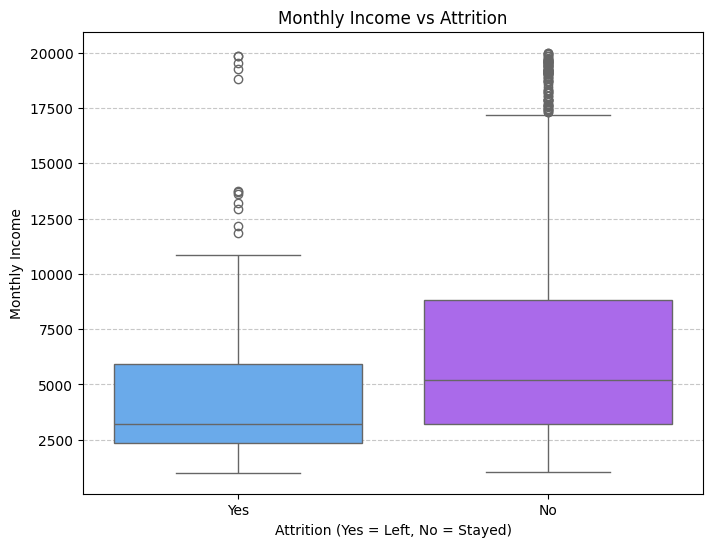

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# create box plot: income vs attrition
plt.figure(figsize=(8, 6))
sns.boxplot(data=attrition, x='Attrition', y='MonthlyIncome', hue="Attrition", palette='cool', legend=False)
plt.title('Monthly Income vs Attrition')
plt.xlabel('Attrition (Yes = Left, No = Stayed)')
plt.ylabel('Monthly Income')
plt.grid(axis='y', linestyle='--', alpha=0.7)

**Interpretation**

This visualization clearly shows a disparity in the central tendency of income. The median monthly income for employees who stayed (No) is visibly higher than those who left (Yes). This suggests that lower compensation is a statistically significant *signal* associated with the likelihood of attrition. 

There are a number of outliers in the stayed (No) category who represent high-earners who remain at the company, and are most likely senior employees or more executive level (as seen by the large monthly salary). The attrition (Yes) group is more tightly grouped at lower monthly income levels which means the model's sensitivity to income as a predictor will be stronger for junior to mid-level positions. Once the model gets to the higher monthly pay it will most likely have a harder time performing.


**Graph 2 Stacked Bar Chart: Overtime vs Attrition**

This will help to visualize if employees are being burned out with overtime and causing them to quit.

(array([0, 1]), [Text(0, 0, 'No'), Text(1, 0, 'Yes')])

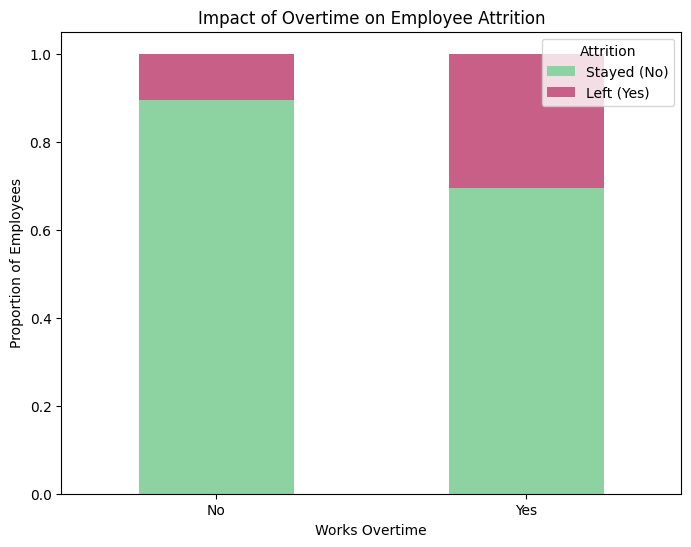

In [9]:
# creating a crosstab for the stacked bar chart
overtime_attrition = pd.crosstab(attrition['OverTime'], attrition['Attrition'], normalize='index')

# plotting
overtime_attrition.plot(kind='bar', stacked=True, color=['#8DD3A2', '#C75F87'], figsize=(8, 6))

plt.title('Impact of Overtime on Employee Attrition')
plt.xlabel('Works Overtime')
plt.ylabel('Proportion of Employees')
plt.legend(title='Attrition', labels=['Stayed (No)', 'Left (Yes)'], loc='upper right')
plt.xticks(rotation=0)

**Interpretation**

This visualization shows a definite correlation between overtime and employee turnover. For those employees not working overtime, attrition is relatively low, however, the proportion of employees who left dramatically increases for those who *do* work overtime. This places overtime as a primary feature with a strong statistical signal for being able to predict future attrition.

This will be a crucial feature to include for model sensitivity. This will help to identify the employees who are at risk for experiencing burnout and possibly quitting.


**Graph 3 Correlation Heatmap: Numeric Features**

This will help to identify any multicollinearity (like Age and years at company) and see which variables have the strongest linear relationship with attrition.

Text(0.5, 1.0, 'Correlation Heatmap of Numeric Features')

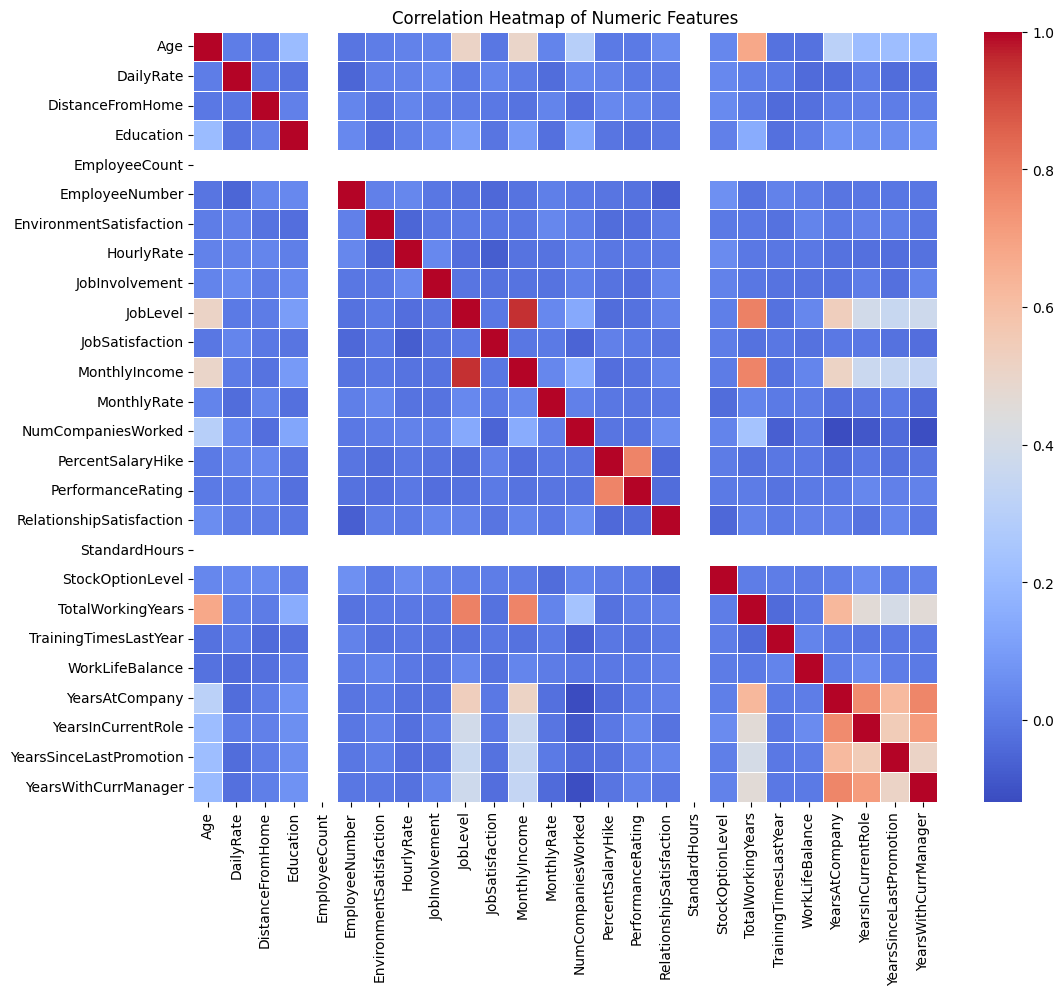

In [19]:
# select numeric features
numeric_attrition = attrition.select_dtypes(include=['number'])

# calculate correlation matrix
corr_matrix = numeric_attrition.corr()

# create the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features')

**Interpretation**

This heatmap identifies strong positive correlations between job level, monthly income, and total working years. This shows, as expected, that both experience and seniority are primary drivers of compensation. With all of these variables providing similar sentiment it may be beneficial to reduce some of these features to prevent overfitting. 

There is also a high correlation between years at company and years with current manager meaning management stability is deeply intertwined with tenure. However, there is a also a lack of strong correlation between additional pay variables, like hourly rate and daily rate, with attrition. This implies these metrics may create noise in the model rather than signal.

One of the most important insights from this heatmap is the identification of multicollinearity. With the high correlation of monthly income, job level, and total working years I will only need to use one or two of these to represent financial/career status in the model and to prevent bias from the same underlying factor appearing three separate times. There is also weak correlation across the other variables which suggests this is a multivariate problem that cannot be solved by looking at a single variable.


**Graph 4 Violin Plot: Attrition Segmented by Marital Status**

This will help to visualize if employees are more likely to quit if they are younger or single compared to someone married and older, and considered *more settled* in their careers.

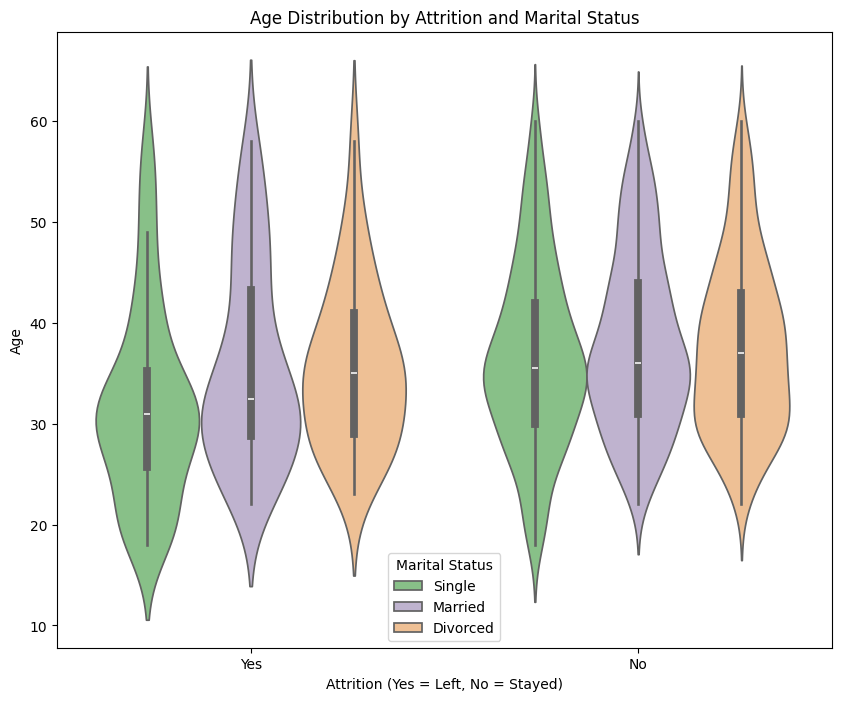

In [19]:
# create the Violin Plot
plt.figure(figsize=(10, 8))
sns.violinplot(data=attrition, x='Attrition', y='Age', hue='MaritalStatus', palette='Accent')

plt.title('Age Distribution by Attrition and Marital Status')
plt.xlabel('Attrition (Yes = Left, No = Stayed)')
plt.ylabel('Age')
plt.legend(title='Marital Status')

**Interpretation**

This plot shows definite signal regarding age. The Yes (on the left) shows that single employees are notably wider at the younger age groups (20-30s) which suggests that life stage and marital status are significant factors in whether the employee stays or quits a company. Single employees have a higher propensity to leave a company compared to married or divorced counterparts where the plots show a more stable, centered distribution. 

The No (on the right) shows a more consistent, bell-shaped distribution across each of the marital status categories, as well as a higher median age. This indicates that the sensitivity of the model will likely be highest when identifying turover risk for early-career employees. Older employees that are either married or divorced will represent the most stable group of the workforce and will be a negative control for the risk of attrition.


### Graphical Analysis Overview/Conclusion

The graphical analysis of this IBM Attrition dataset provided evidence that employee turnover rates are not just random occurrences but a multi-faceted business problem that is driven by specific demographic, operational, and financial indicators. The primary variable identified during this initial analysis is the intersection of pay and workload. The Monthly Income box plot confirmed that employees who leave companies tend to do so when they are at lower salary bands which suggests that companies lose talentend employees to competitors offering higher entry-level or mid-level wages. It is also known, in some fields (like software engineering), that the only way to get a promotion is to job hop. The Overtime Stacked bar chart also provided clear evidence of burnout being a huge reason for employee attrition. Employees who work overtime had a significant increase in attrition rates. To ensure covering of the demographic portion, the Violin Plot and Marital Status revealed that younger, single employees are more likely to leave a job. This could indicate that companies are not investing in the early career development of their employees enough. The correlation heatmap indicated redundant variables in job level, total working years, and monthly income which will need to be considered as a single variable of *Seniority* to avoid the statistical noise of multicollinearity.

Based on these insights the proposed model will focus on a multi-pronged approach to indentifying turnover risk. High-risk individuals for attrition have been identified as younger, lower-paid and frequently working overtime. In the modeling phase recall will be important to ensure that the model will be sensitive enough to catch these high risk employees even if employees who are not planning to leave are flagged for HR intervention. This strategy will help the HR department to maximize their return on investment for retention efforts, which will directly address the underlying business problem of high replacement costs and loss of institutional knowledge. 